[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C10/E10-3_Banc_MotoPompe_V2_CORRIGE.ipynb)

# Banc moteur et pompe : apprendre la frontière du fonctionnement normal

## Le contexte

Un banc d'essai fait tourner un groupe moteur et pompe à trois vitesses de consigne, avec une vanne d'ouverture variable. À chaque relevé, six mesures sont enregistrées : couple, courant, température des enroulements, vibration, pression et débit. Ces mesures ne sont pas libres : la pompe, le moteur et l'échauffement les relient par des lois. Quelques relevés trahissent un défaut, une fuite interne, un échauffement anormal ou un capteur de courant qui dérive, mais personne ne les a repérés, et aucune colonne ne les désigne.

On voudrait un détecteur qui apprenne à quoi ressemble le fonctionnement normal, puis signale tout relevé qui sort de cette frontière. Une fausse alerte coûte une inspection inutile ; un défaut laissé passer peut coûter la pompe. Le détecteur n'apprend jamais à partir de la réponse : c'est un problème de détection d'anomalies sans étiquette.

Défi : signaler les relevés anormaux parmi les 600 relevés, et obtenir un F-score macro supérieur à celui du modèle de départ. Le F-score macro est la moyenne des F-scores des deux classes, normal et anormal : il pèse autant la classe rare que la classe fréquente. Le modèle de départ est un SVM à une classe sur les mesures mises à l'échelle, avec un budget d'alerte de 10 % ; il atteint 0,6968 : à vous de faire mieux. La colonne de référence ne sert qu'à noter, une seule fois, à la fin.

## Les données

Fichier `MecaIA-Banc_MotoPompe_V2.xlsx`, dans le dossier `donnees` du dépôt : 600 relevés, 7 colonnes. Une ligne est un relevé du banc.

| Colonne | Signification | Unité |
|---|---|---|
| `couple_charge_Nm` | couple sur l'arbre du moteur | N·m |
| `courant_moteur_A` | courant absorbé par le moteur | A |
| `temperature_enroulement_C` | température des enroulements | °C |
| `vibration_rms_mm_s` | vitesse de vibration efficace du palier | mm/s |
| `pression_hydraulique_bar` | pression de refoulement | bar |
| `debit_hydraulique_L_min` | débit de la pompe | L/min |
| `defaut_reference` | 1 pour un relevé anormal, établi après coup, pour noter seulement | 0 ou 1 |

Origine : jeu simulé, un banc moteur et pompe à trois consignes de vitesse dont les mesures suivent les lois de similitude, de rendement et d'échauffement, auquel s'ajoutent des relevés de combinaison anormale. Le jeu enseigne une méthode et ne remplace pas une étude de surveillance. La colonne `defaut_reference` n'est jamais une entrée du modèle, et ce corrigé ne la lit qu'à la dernière cellule, pour calculer le score.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on désigne les mesures par exclusion de la colonne de référence. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Banc_MotoPompe_V2.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Banc_MotoPompe_V2.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

colonne_cachee = "defaut_reference"
mesures = [colonne for colonne in df.columns if colonne != colonne_cachee]
X = df[mesures]
print("dimensions des mesures :", X.shape)
print("cases vides au total :", int(X.isna().sum().sum()))
print(X.describe().loc[["min", "50%", "max"]].round(1).T.to_string())

dimensions des mesures : (600, 6)
cases vides au total : 0
                            min    50%    max
couple_charge_Nm           31.5  110.2  203.3
courant_moteur_A            7.4   29.0   65.1
temperature_enroulement_C  34.7   46.1   91.5
vibration_rms_mm_s          1.8    5.1    8.2
pression_hydraulique_bar   10.6   53.8  128.8
debit_hydraulique_L_min    24.8  110.5  204.1


Lecture du résultat : 600 relevés, 6 mesures, aucune case vide. Les six mesures ont des unités et des ordres de grandeur très différents : le couple va de 32 à 203 N·m, la vibration de 1,8 à 8,2 mm/s. Un détecteur fondé sur des distances demandera de les mettre à l'échelle.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Banc_MotoPompe_V2.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : pas de base de test

Un détecteur sans étiquette n'a pas de réponse à prédire : il apprend le fonctionnement habituel sur tous les relevés, qui contiennent eux-mêmes quelques relevés anormaux, comme tout historique réel. Il n'y a donc pas de découpage entre apprentissage et test ; la base de test du défi est le jeu entier, et le score se calcule une seule fois, à la dernière cellule. Jusque-là, aucune cellule ne lit la colonne de référence.

### Étape 3 : regarder les relations entre les mesures

Deux vues suffisent à voir que les mesures sont liées : la pression contre le débit (la courbe de la pompe), et le courant contre le couple (le moteur). Tous les points sont gris : on ne sait pas quels relevés sont anormaux.

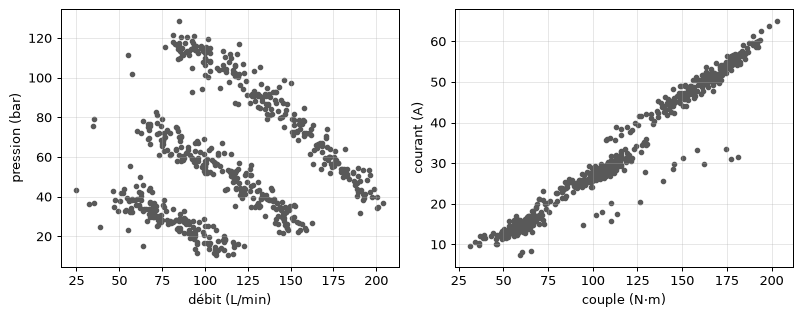

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].scatter(X["debit_hydraulique_L_min"], X["pression_hydraulique_bar"], s=12, color="0.35")
axes[0].set_xlabel("débit (L/min)")
axes[0].set_ylabel("pression (bar)")
axes[1].scatter(X["couple_charge_Nm"], X["courant_moteur_A"], s=12, color="0.35")
axes[1].set_xlabel("couple (N·m)")
axes[1].set_ylabel("courant (A)")
for axe in axes:
    axe.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Lecture du résultat : les relevés se rangent le long de courbes étroites. La pression baisse quand le débit monte, et le courant croît presque en droite avec le couple. Un point qui s'écarte de ces courbes reste pourtant dans la plage de chaque axe : c'est la combinaison des mesures qui le trahit, pas une mesure seule.

### Étape 4 : essayer la règle la plus simple

La règle de Tukey, déjà vue pour les valeurs aberrantes, signale tout relevé dont une mesure sort de l'intervalle de largeur 1,5 fois l'écart interquartile autour des quartiles. Elle regarde chaque mesure seule, sans apprentissage.

In [3]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
ecart = q3 - q1
hors = (X < q1 - 1.5 * ecart) | (X > q3 + 1.5 * ecart)
print("relevés hors bornes, par mesure :")
print(hors.sum().to_string())
print("relevés signalés au total :", int(hors.any(axis=1).sum()))

relevés hors bornes, par mesure :
couple_charge_Nm             0
courant_moteur_A             0
temperature_enroulement_C    0
vibration_rms_mm_s           0
pression_hydraulique_bar     0
debit_hydraulique_L_min      0
relevés signalés au total : 0


Lecture du résultat : la règle de Tukey signale 0 relevé sur 600. Chaque mesure, prise seule, reste dans sa plage habituelle : si le banc a des relevés anormaux, ils se cachent dans les combinaisons. Il faut un détecteur qui apprenne la frontière du fonctionnement normal dans l'espace des six mesures.

### Étape 5 : construire le modèle de départ

Le SVM à une classe apprend une frontière autour de l'essentiel des relevés. Son paramètre `nu` fixe la part maximale de relevés laissés hors de la frontière, donc le budget d'alerte : ici 10 %, soit une inspection sur dix au plus. Le noyau gaussien, avec son réglage par défaut `gamma="scale"`, donne à la frontière une forme souple. Les mesures sont mises à l'échelle d'abord, sur les relevés eux-mêmes. La méthode `predict` rend 1 pour un relevé jugé normal et -1 pour un relevé jugé anormal.

In [4]:
# Solution :
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

model = make_pipeline(StandardScaler(), OneClassSVM(nu=0.1, gamma="scale"))
model.fit(X)
alerte = (model.predict(X) == -1).astype(int)           # 1 : relevé suspect
print("relevés signalés :", int(alerte.sum()), "sur", len(alerte))
# Fin de la solution

relevés signalés : 59 sur 600


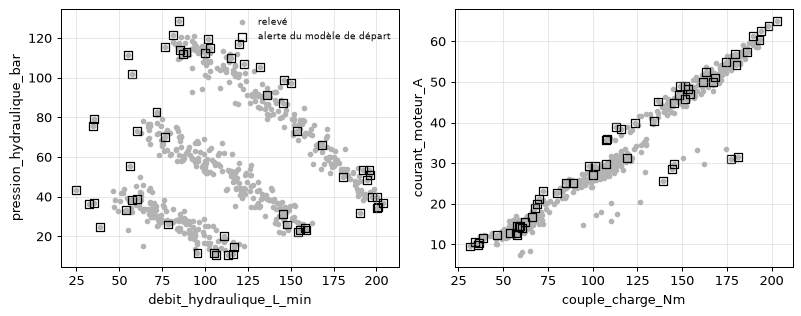

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for axe, (abscisse, ordonnee) in zip(axes, [("debit_hydraulique_L_min", "pression_hydraulique_bar"),
                                              ("couple_charge_Nm", "courant_moteur_A")]):
    axe.scatter(X[abscisse], X[ordonnee], s=12, color="0.7", label="relevé")
    axe.scatter(X.loc[alerte == 1, abscisse], X.loc[alerte == 1, ordonnee], s=40, marker="s",
                facecolor="none", edgecolor="black", label="alerte du modèle de départ")
    axe.set_xlabel(abscisse)
    axe.set_ylabel(ordonnee)
    axe.grid(alpha=0.3)
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

Lecture du résultat : le modèle signale 59 relevés sur 600, soit 9,8 %, à peu près le budget fixé. Les carrés vides de la figure marquent ces alertes. La qualité de ces alertes, leur précision et leur rappel, se mesure à la dernière cellule, une seule fois.

## Pour aller plus loin : le budget d'alerte, le blanchiment et d'autres détecteurs

Le modèle de départ de l'étape 5 reste le score de référence du défi. La cellule suivante construit des détecteurs concurrents, toujours sans la colonne de référence : le SVM à une classe avec son budget par défaut (`nu=0.5`), le même SVM après blanchiment par analyse en composantes principales (qui donne la même variance à toutes les directions et révèle les écarts à la courbe), la forêt d'isolement et le facteur d'anomalie local, avec le même budget de 10 %. Leurs scores se lisent à la dernière cellule, une fois.

In [6]:
# Solution :
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

Z = StandardScaler().fit_transform(X)
alertes = {
    "règle de Tukey, mesure par mesure": hors.any(axis=1).astype(int).to_numpy(),
    "SVM à une classe, nu 0,5 (réglage par défaut)":
        (make_pipeline(StandardScaler(), OneClassSVM(nu=0.5)).fit(X).predict(X) == -1).astype(int),
    "SVM à une classe, nu 0,1 (modèle de départ)": alerte,
    "SVM à une classe, mesures blanchies":
        (make_pipeline(StandardScaler(), PCA(whiten=True, random_state=GRAINE), OneClassSVM(nu=0.1, gamma=0.1))
         .fit(X).predict(X) == -1).astype(int),
    "forêt d'isolement, 10 % d'alertes":
        (IsolationForest(contamination=0.1, random_state=GRAINE).fit(Z).predict(Z) == -1).astype(int),
    "facteur d'anomalie local, 20 voisins, 10 % d'alertes":
        (LocalOutlierFactor(n_neighbors=20, contamination=0.1).fit_predict(Z) == -1).astype(int)}
for nom, a in alertes.items():
    print(f"{nom} : {int(a.sum())} relevés signalés")
# Fin de la solution

règle de Tukey, mesure par mesure : 0 relevés signalés
SVM à une classe, nu 0,5 (réglage par défaut) : 301 relevés signalés
SVM à une classe, nu 0,1 (modèle de départ) : 59 relevés signalés
SVM à une classe, mesures blanchies : 66 relevés signalés
forêt d'isolement, 10 % d'alertes : 60 relevés signalés
facteur d'anomalie local, 20 voisins, 10 % d'alertes : 60 relevés signalés


## Le score de référence

Le score publié est le F-score macro du modèle de départ de l'étape 5, calculé sur tous les relevés contre la colonne de référence. Un témoin sans apprentissage ne signale jamais rien. L'empreinte identifie la base de test, ici tous les relevés.

In [7]:
import hashlib

from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

reference = df[colonne_cachee]
score = f1_score(reference, alerte, average="macro")
score_temoin = f1_score(reference, np.zeros(len(df), dtype=int), average="macro")
positions = ",".join(str(i) for i in sorted(df.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print(f"témoin qui ne signale jamais rien : {score_temoin:.4f}")
print(f"précision : {precision_score(reference, alerte):.3f}, rappel : {recall_score(reference, alerte):.3f}")
print("matrice de confusion (lignes : réel, colonnes : prédit ; anormal, normal)")
print(confusion_matrix(reference, alerte, labels=[1, 0]))
print("SCORE_REFERENCE f1_macro = %.4f" % score)
# Solution :
f1_candidats = {nom: f1_score(reference, a, average="macro") for nom, a in alertes.items()}
for nom, valeur in f1_candidats.items():
    print(f"{nom} : F-score macro {valeur:.4f}")
# Fin de la solution

EMPREINTE_TEST = 439f3a6b5500d0c863fc6e848e7c568e10ce32f71c6dab87f01cb9a35602ccfb
témoin qui ne signale jamais rien : 0.4737
précision : 0.458, rappel : 0.450
matrice de confusion (lignes : réel, colonnes : prédit ; anormal, normal)
[[ 27  33]
 [ 32 508]]
SCORE_REFERENCE f1_macro = 0.6968
règle de Tukey, mesure par mesure : F-score macro 0.4737
SVM à une classe, nu 0,5 (réglage par défaut) : F-score macro 0.4948
SVM à une classe, nu 0,1 (modèle de départ) : F-score macro 0.6968
SVM à une classe, mesures blanchies : F-score macro 0.7783
forêt d'isolement, 10 % d'alertes : F-score macro 0.6296
facteur d'anomalie local, 20 voisins, 10 % d'alertes : F-score macro 0.8704


## Synthèse

1. Un détecteur sans étiquette ne se juge pas sur lui-même : la colonne de référence, cachée jusqu'à la fin, sert à noter. Le modèle de départ atteint 0,6968, contre 0,4737 pour le témoin qui ne signale jamais rien.
2. La règle de Tukey, qui regarde chaque mesure seule, n'apporte rien ici (0,4737) : les défauts sont des combinaisons, et chaque valeur reste dans sa plage.
3. Le paramètre `nu` est le budget d'alerte : avec le réglage par défaut (0,5), le SVM signale la moitié des relevés et tombe à 0,4948.
4. Le blanchiment donne la même variance à toutes les directions : le SVM à une classe monte à 0,7783. La forêt d'isolement atteint 0,6296.
5. Sur ce banc, le facteur d'anomalie local, qui juge la densité autour de chaque relevé, donne 0,8704 : meilleur que le SVM à une classe, dont la frontière globale d'un noyau gaussien peut mal suivre des courbes étroites. Un relevé signalé reste un relevé inhabituel, que seule une inspection qualifie.